In [1]:
import os
import time
import random
import pathlib
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
import tensorflow as tf
from tensorflow.keras import layers, models, backend as K
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix

SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print(f"Executing on GPU: {gpus[0].name}")
    except RuntimeError as e:
        print(e)
else:
    print("Warning: Running on CPU. Ensure GPU accelerator is enabled.")

Executing on GPU: /physical_device:GPU:0


In [8]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
NUM_CLASSES = 5
CLASS_NAMES = ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']

dataset_url = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"
downloaded_path = tf.keras.utils.get_file('flower_photos', origin=dataset_url, untar=True)
data_dir = pathlib.Path(downloaded_path)

if (data_dir / 'flower_photos').is_dir():
    data_dir = data_dir / 'flower_photos'

print(f"Dataset root: {data_dir}")

# Load 70% Train, 30% remainder
raw_train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    labels='inferred',
    label_mode='int',
    class_names=CLASS_NAMES,
    validation_split=0.30,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=None,
    shuffle=True
)

raw_remainder_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    labels='inferred',
    label_mode='int',
    class_names=CLASS_NAMES,
    validation_split=0.30,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=None,
    shuffle=False
)

remainder_size = len(raw_remainder_ds)
val_size = remainder_size // 2

raw_val_ds = raw_remainder_ds.take(val_size)
raw_test_ds = raw_remainder_ds.skip(val_size)

print(f"Partitions -> Train: {len(raw_train_ds)}, Val: {len(raw_val_ds)}, Test: {len(raw_test_ds)}")

def preprocess_train(image, label):
    image = tf.image.random_flip_left_right(image)
    image = tf.image.random_brightness(image, max_delta=0.1)
    image = tf.image.random_contrast(image, lower=0.9, upper=1.1)
    image = tf.keras.applications.resnet50.preprocess_input(image)
    label = tf.one_hot(label, NUM_CLASSES)
    return image, label

def preprocess_eval(image, label):
    image = tf.keras.applications.resnet50.preprocess_input(image)
    label = tf.one_hot(label, NUM_CLASSES)
    return image, label

train_loader = (
    raw_train_ds.shuffle(1000, seed=SEED)
    .map(preprocess_train, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

val_loader = (
    raw_val_ds.map(preprocess_eval, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

test_loader = (
    raw_test_ds.map(preprocess_eval, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

def deprocess_img(img):
    x = img.copy()
    x[:, :, 0] += 103.939
    x[:, :, 1] += 116.779
    x[:, :, 2] += 123.68
    x = x[:, :, ::-1]
    return np.clip(x, 0, 255).astype(np.uint8)

Dataset root: /root/.keras/datasets/flower_photos/flower_photos
Found 3670 files belonging to 5 classes.
Using 2569 files for training.
Found 3670 files belonging to 5 classes.
Using 1101 files for validation.
Partitions -> Train: 2569, Val: 550, Test: 551


In [6]:
STAGE_LAYERS = {
    'P1': 'conv2_block3_out',
    'P2': 'conv3_block4_out',
    'P3': 'conv4_block6_out',
    'P4': 'conv5_block3_out'
}

STAGE_CHANNELS = {'P1': 256, 'P2': 512, 'P3': 1024, 'P4': 2048}

class ChannelAttention(layers.Layer):
    def __init__(self, channels, ratio=16, **kwargs):
        super(ChannelAttention, self).__init__(**kwargs)
        self.channels = channels
        reduced_ch = max(1, channels // ratio)
        self.fc1 = layers.Dense(reduced_ch, activation='relu', use_bias=False)
        self.fc2 = layers.Dense(channels, activation='sigmoid', use_bias=False)

    def call(self, inputs):
        gap = tf.reduce_mean(inputs, axis=[1, 2], keepdims=False)
        weights = self.fc2(self.fc1(gap))
        return inputs * tf.reshape(weights, [-1, 1, 1, self.channels])

    def get_attention_weights(self, inputs):
        gap = tf.reduce_mean(inputs, axis=[1, 2], keepdims=False)
        return self.fc2(self.fc1(gap))

class SpatialAttention(layers.Layer):
    def __init__(self, kernel_size=7, **kwargs):
        super(SpatialAttention, self).__init__(**kwargs)
        self.conv = layers.Conv2D(1, kernel_size=kernel_size, padding='same', activation='sigmoid', use_bias=False)

    def call(self, inputs):
        avg_pool = tf.reduce_mean(inputs, axis=-1, keepdims=True)
        max_pool = tf.reduce_max(inputs, axis=-1, keepdims=True)
        return inputs * self.conv(tf.concat([avg_pool, max_pool], axis=-1))

    def get_spatial_map(self, inputs):
        avg_pool = tf.reduce_mean(inputs, axis=-1, keepdims=True)
        max_pool = tf.reduce_max(inputs, axis=-1, keepdims=True)
        return self.conv(tf.concat([avg_pool, max_pool], axis=-1))

class SequentialChannelSpatialAttention(layers.Layer):
    def __init__(self, channels, ratio=16, kernel_size=7, **kwargs):
        super(SequentialChannelSpatialAttention, self).__init__(**kwargs)
        self.ca = ChannelAttention(channels, ratio=ratio)
        self.sa = SpatialAttention(kernel_size=kernel_size)

    def call(self, inputs):
        return self.sa(self.ca(inputs))

class ReverseChannelSpatialAttention(layers.Layer):
    def __init__(self, channels, ratio=16, kernel_size=7, **kwargs):
        super(ReverseChannelSpatialAttention, self).__init__(**kwargs)
        self.sa = SpatialAttention(kernel_size=kernel_size)
        self.ca = ChannelAttention(channels, ratio=ratio)

    def call(self, inputs):
        return self.ca(self.sa(inputs))

class LightweightSelfAttention(layers.Layer):
    def __init__(self, channels, d_k=None, **kwargs):
        super(LightweightSelfAttention, self).__init__(**kwargs)
        self.channels = channels
        self.d_k = d_k if d_k is not None else max(16, channels // 8)
        self.query = layers.Conv2D(self.d_k, 1, use_bias=False)
        self.key = layers.Conv2D(self.d_k, 1, use_bias=False)
        self.value = layers.Conv2D(channels, 1, use_bias=False)
        self.gamma = self.add_weight(name='gamma', shape=[1], initializer='zeros', trainable=True)

    def call(self, inputs):
        B = tf.shape(inputs)[0]
        H = tf.shape(inputs)[1]
        W = tf.shape(inputs)[2]
        N = H * W
        Q = tf.reshape(self.query(inputs), [B, N, self.d_k])
        K_mat = tf.reshape(self.key(inputs), [B, N, self.d_k])
        V = tf.reshape(self.value(inputs), [B, N, self.channels])
        scores = tf.matmul(Q, K_mat, transpose_b=True) / tf.math.sqrt(tf.cast(self.d_k, tf.float32))
        attn_matrix = tf.nn.softmax(scores, axis=-1)
        Y = tf.reshape(tf.matmul(attn_matrix, V), [B, H, W, self.channels])
        return inputs + self.gamma * Y

class ECALayer(layers.Layer):
    def __init__(self, k_size=3, **kwargs):
        super(ECALayer, self).__init__(**kwargs)
        self.conv1d = layers.Conv1D(1, kernel_size=k_size, padding='same', use_bias=False)

    def call(self, inputs):
        gap = tf.reduce_mean(inputs, axis=[1, 2], keepdims=True)
        gap_t = tf.transpose(tf.squeeze(gap, axis=1), [0, 2, 1])
        w = tf.transpose(self.conv1d(gap_t), [0, 2, 1])
        return inputs * tf.expand_dims(tf.nn.sigmoid(w), axis=1)

class CBAMBlock(layers.Layer):
    def __init__(self, channels, ratio=16, kernel_size=7, **kwargs):
        super(CBAMBlock, self).__init__(**kwargs)
        self.channels = channels
        reduced_ch = max(1, channels // ratio)
        self.fc1 = layers.Dense(reduced_ch, activation='relu', use_bias=False)
        self.fc2 = layers.Dense(channels, use_bias=False)
        self.sa = SpatialAttention(kernel_size=kernel_size)

    def call(self, inputs):
        gap = tf.reduce_mean(inputs, axis=[1, 2], keepdims=False)
        gmp = tf.reduce_max(inputs, axis=[1, 2], keepdims=False)
        weights = tf.nn.sigmoid(self.fc2(self.fc1(gap)) + self.fc2(self.fc1(gmp)))
        x = inputs * tf.reshape(weights, [-1, 1, 1, self.channels])
        return self.sa(x)

class CoordinateAttention(layers.Layer):
    def __init__(self, channels, reduction=32, **kwargs):
        super(CoordinateAttention, self).__init__(**kwargs)
        self.channels = channels
        reduced_ch = max(8, channels // reduction)
        self.conv1 = layers.Conv2D(reduced_ch, 1, padding='same')
        self.bn = layers.BatchNormalization()
        self.act = layers.Activation('relu')
        self.conv_h = layers.Conv2D(channels, 1, padding='same')
        self.conv_w = layers.Conv2D(channels, 1, padding='same')

    def call(self, inputs):
        H, W = tf.shape(inputs)[1], tf.shape(inputs)[2]
        x_h = tf.reduce_mean(inputs, axis=2, keepdims=True)
        x_w = tf.transpose(tf.reduce_mean(inputs, axis=1, keepdims=True), [0, 2, 1, 3])
        f = self.act(self.bn(self.conv1(tf.concat([x_h, x_w], axis=1))))
        f_h, f_w_t = tf.split(f, [H, W], axis=1)
        s_h = tf.nn.sigmoid(self.conv_h(f_h))
        s_w = tf.nn.sigmoid(self.conv_w(tf.transpose(f_w_t, [0, 2, 1, 3])))
        return inputs * s_h * s_w

In [9]:
# =========================================================================
# COMBINED BLOCK: MODEL BUILDER + TRAINING FUNCTION + EXPERIMENT EXECUTION
# =========================================================================

def build_universal_model(attn_type=None, positions=['P3'], spatial_kernel=7):
    K.clear_session()
    base_resnet = tf.keras.applications.ResNet50(
        include_top=False, weights='imagenet', input_shape=(224, 224, 3)
    )
    inputs = tf.keras.Input(shape=(224, 224, 3), name='input_image')

    if attn_type is None or positions == ['None']:
        features = base_resnet(inputs)
        x = layers.GlobalAveragePooling2D(name='gap')(features)
        x = layers.Dropout(0.3, name='dropout')(x)
        outputs = layers.Dense(NUM_CLASSES, activation='softmax', name='predictions')(x)
        model = models.Model(inputs=inputs, outputs=outputs, name='ResNet50_Baseline')
        return model, base_resnet

    target_pos = positions[-1]
    target_layer_name = STAGE_LAYERS[target_pos]
    target_channels = STAGE_CHANNELS[target_pos]

    feature_extractor = models.Model(
        inputs=base_resnet.input,
        outputs=base_resnet.get_layer(target_layer_name).output,
        name=f"extractor_{target_pos}"
    )
    features = feature_extractor(inputs)

    if attn_type == 'channel':
        attn = ChannelAttention(target_channels)
    elif attn_type == 'spatial' or attn_type == 'spatial_k':
        attn = SpatialAttention(kernel_size=spatial_kernel)
    elif attn_type == 'channel_spatial':
        attn = SequentialChannelSpatialAttention(target_channels, kernel_size=spatial_kernel)
    elif attn_type == 'spatial_channel_rev':
        attn = ReverseChannelSpatialAttention(target_channels, kernel_size=spatial_kernel)
    elif attn_type == 'self_attention':
        attn = LightweightSelfAttention(target_channels)
    elif attn_type == 'eca':
        attn = ECALayer(k_size=3)
    elif attn_type == 'cbam':
        attn = CBAMBlock(target_channels, kernel_size=spatial_kernel)
    elif attn_type == 'coord_attn':
        attn = CoordinateAttention(target_channels)
    else:
        raise ValueError(f"Unknown attention type: {attn_type}")

    attended_features = attn(features)

    x = layers.GlobalAveragePooling2D(name='gap')(attended_features)
    x = layers.Dropout(0.3, name='dropout')(x)
    outputs = layers.Dense(NUM_CLASSES, activation='softmax', name='predictions')(x)

    safe_pos_name = "_".join(positions)
    model = models.Model(
        inputs=inputs,
        outputs=outputs,
        name=f"ResNet50_{attn_type}_{safe_pos_name}"
    )
    return model, base_resnet


def train_and_evaluate(model, base_resnet, epochs_warmup=3, epochs_finetune=5):
    for layer in model.layers:
        if layer.name.startswith(('conv', 'res', 'bn', 'extractor')):
            layer.trainable = False
        else:
            layer.trainable = True

    model.compile(
        optimizer=tf.keras.optimizers.Adam(1e-3),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    print(f"\n--- Phase 1: Warmup ({epochs_warmup} epochs) for {model.name} ---")
    h1 = model.fit(train_loader, validation_data=val_loader, epochs=epochs_warmup, verbose=1)

    for layer in model.layers:
        if 'extractor' in layer.name:
            layer.trainable = True

    model.compile(
        optimizer=tf.keras.optimizers.Adam(1e-4),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    print(f"--- Phase 2: Fine-Tuning ({epochs_finetune} epochs) for {model.name} ---")
    h2 = model.fit(train_loader, validation_data=val_loader, epochs=epochs_finetune, verbose=1)

    history = {k: h1.history[k] + h2.history[k] for k in h1.history.keys()}

    y_true, y_pred = [], []
    inference_times = []
    for images, labels in test_loader:
        t0 = time.time()
        preds = model(images, training=False)
        t1 = time.time()
        inference_times.append((t1 - t0) / len(images))
        y_true.extend(np.argmax(labels.numpy(), axis=-1))
        y_pred.extend(np.argmax(preds.numpy(), axis=-1))

    acc = accuracy_score(y_true, y_pred)
    prec, rec, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average='macro', zero_division=0
    )

    return {
        'model_name': model.name,
        'accuracy': float(acc),
        'precision': float(prec),
        'recall': float(rec),
        'f1': float(f1),
        'trainable_params': int(sum([K.count_params(w) for w in model.trainable_weights])),
        'total_params': int(model.count_params()),
        'inference_time_ms': float(np.mean(inference_times) * 1000),
        'y_true': y_true,
        'y_pred': y_pred,
        'history': history
    }


# --- RUN ALL 15 EXPERIMENT CONFIGURATIONS ---
all_experiments = [
    {'name': 'Baseline',              'type': None,                    'pos': ['None'],          'k': 7},
    {'name': 'Channel Attn',          'type': 'channel',               'pos': ['P3'],            'k': 7},
    {'name': 'Spatial Attn',          'type': 'spatial',               'pos': ['P3'],            'k': 7},
    {'name': 'Channel+Spatial (P2)',  'type': 'channel_spatial',       'pos': ['P2'],            'k': 7},
    {'name': 'Channel+Spatial (P3)',  'type': 'channel_spatial',       'pos': ['P3'],            'k': 7},
    {'name': 'Channel+Spatial (P4)',  'type': 'channel_spatial',       'pos': ['P4'],            'k': 7},
    {'name': 'Self-Attention',        'type': 'self_attention',        'pos': ['P3'],            'k': 7},
    {'name': 'ECA (Addl)',            'type': 'eca',                   'pos': ['P3'],            'k': 7},
    {'name': 'CS Attn P3_P4',         'type': 'channel_spatial',       'pos': ['P3', 'P4'],      'k': 7},
    {'name': 'CS Attn P2_P3_P4',      'type': 'channel_spatial',       'pos': ['P2', 'P3', 'P4'],'k': 7},
    {'name': 'Spatial_to_Channel P3', 'type': 'spatial_channel_rev',   'pos': ['P3'],            'k': 7},
    {'name': 'Spatial k3 P3',         'type': 'spatial_k',             'pos': ['P3'],            'k': 3},
    {'name': 'Spatial k5 P3',         'type': 'spatial_k',             'pos': ['P3'],            'k': 5},
    {'name': 'CBAM P3',               'type': 'cbam',                  'pos': ['P3'],            'k': 7},
    {'name': 'Coord Attention P3',    'type': 'coord_attn',            'pos': ['P3'],            'k': 7},
]

results = []
trained_models = {}

for exp in all_experiments:
    pos_display = "+".join(exp['pos'])
    pos_key = "_".join(exp['pos'])
    print("\n" + "=" * 60)
    print(f" Training: {exp['name']} | Stages: {pos_display} | Kernel: {exp['k']}")
    print("=" * 60)

    m, base_r = build_universal_model(exp['type'], exp['pos'], spatial_kernel=exp['k'])
    res = train_and_evaluate(m, base_r, epochs_warmup=3, epochs_finetune=5)

    res['position'] = pos_display
    res['experiment_name'] = exp['name']
    results.append(res)
    trained_models[f"{exp['name']}_{pos_key}"] = m


 Training: Baseline | Stages: None | Kernel: 7
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

--- Phase 1: Warmup (3 epochs) for ResNet50_Baseline ---
Epoch 1/3
 2/81 ━━━━━━━━━━━━━━━━━━━━ 6s 81ms/step - accuracy: 0.1094 - loss: 2.7285  

I0000 00:00:1792491027.571415     146 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


81/81 ━━━━━━━━━━━━━━━━━━━━ 33s 234ms/step - accuracy: 0.7084 - loss: 0.8195 - val_accuracy: 0.8764 - val_loss: 0.3711
Epoch 2/3
81/81 ━━━━━━━━━━━━━━━━━━━━ 9s 102ms/step - accuracy: 0.8801 - loss: 0.3310 - val_accuracy: 0.9273 - val_loss: 0.2422
Epoch 3/3
81/81 ━━━━━━━━━━━━━━━━━━━━ 9s 103ms/step - accuracy: 0.9058 - loss: 0.2611 - val_accuracy: 0.9327 - val_loss: 0.2128
--- Phase 2: Fine-Tuning (5 epochs) for ResNet50_Baseline ---
Epoch 1/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 28s 215ms/step - accuracy: 0.9284 - loss: 0.2122 - val_accuracy: 0.9327 - val_loss: 0.2301
Epoch 2/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 10s 108ms/step - accuracy: 0.9249 - loss: 0.2125 - val_accuracy: 0.9382 - val_loss: 0.2110
Epoch 3/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 10s 113ms/step - accuracy: 0.9334 - loss: 0.1965 - val_accuracy: 0.9400 - val_loss: 0.2122
Epoch 4/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 10s 118ms/step - accuracy: 0.9323 - loss: 0.1994 - val_accuracy: 0.9345 - val_loss: 0.2242
Epoch 5/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 10s 112ms/step - 


Experiment Model             | Position   | Acc     | Prec    | Recall  | F1      | Params(M) | Latency(ms)
----------------------------------------------------------------------------------------------------------
Baseline                     | None       | 0.8966  | 0.2000  | 0.1793  | 0.1891  | 23.60     | 12.78     
Channel Attn                 | P3         | 0.9619  | 0.2500  | 0.2405  | 0.2451  | 8.73      | 7.48      
Spatial Attn                 | P3         | 0.9492  | 0.2500  | 0.2373  | 0.2435  | 8.59      | 7.58      
Channel+Spatial (P2)         | P2         | 0.8258  | 0.2000  | 0.1652  | 0.1809  | 1.50      | 4.99      
Channel+Spatial (P3)         | P3         | 0.9619  | 0.2000  | 0.1924  | 0.1961  | 8.73      | 7.60      
Channel+Spatial (P4)         | P4         | 0.9492  | 0.2500  | 0.2373  | 0.2435  | 24.12     | 9.26      
Self-Attention               | P3         | 0.8711  | 0.2000  | 0.1742  | 0.1862  | 9.91      | 7.67      
ECA (Addl)                   | P3  

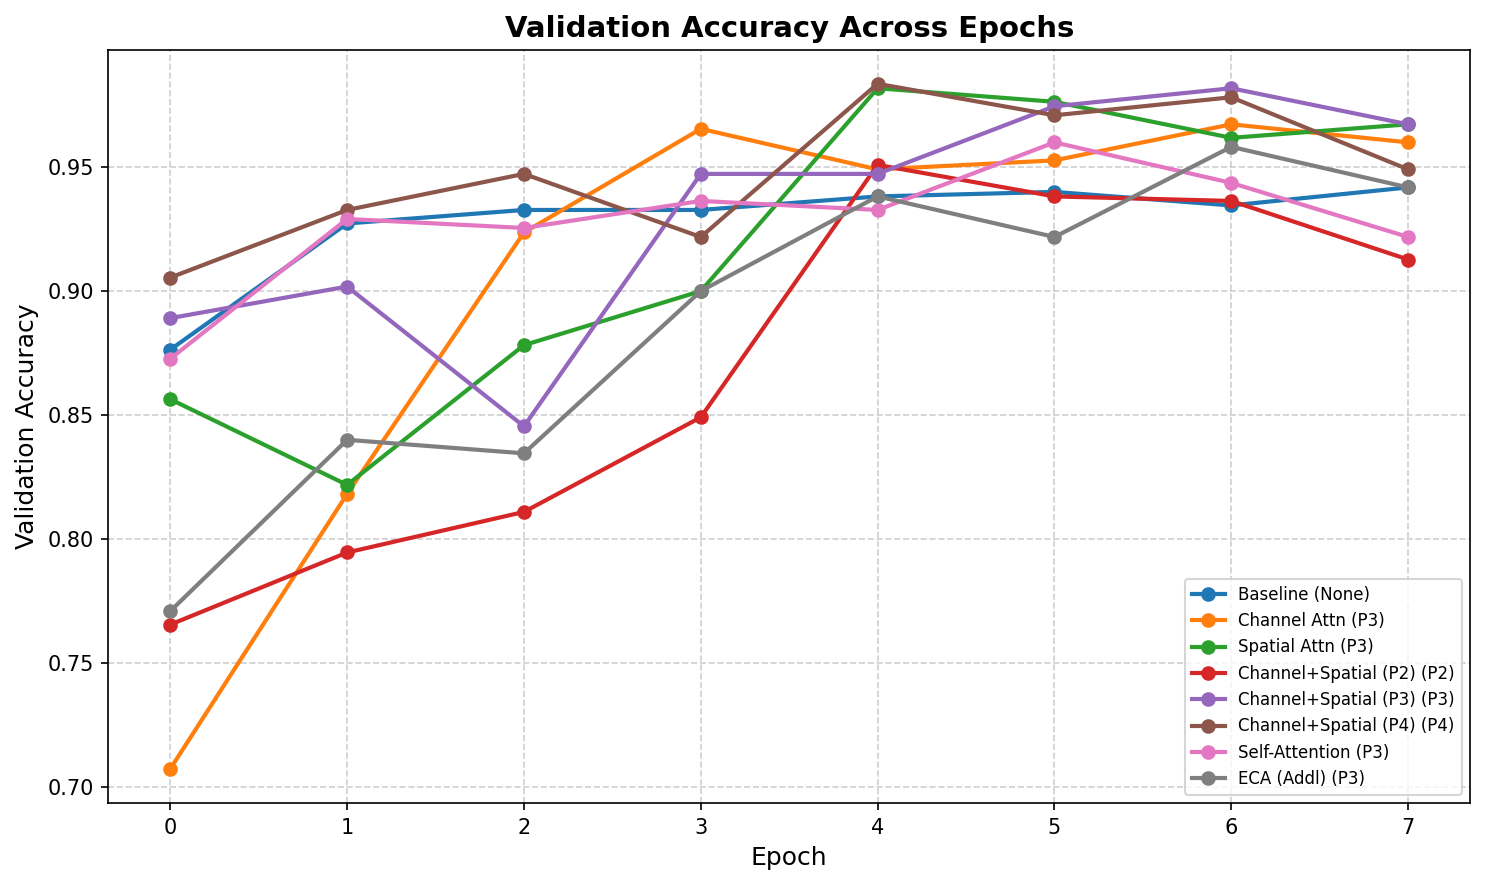

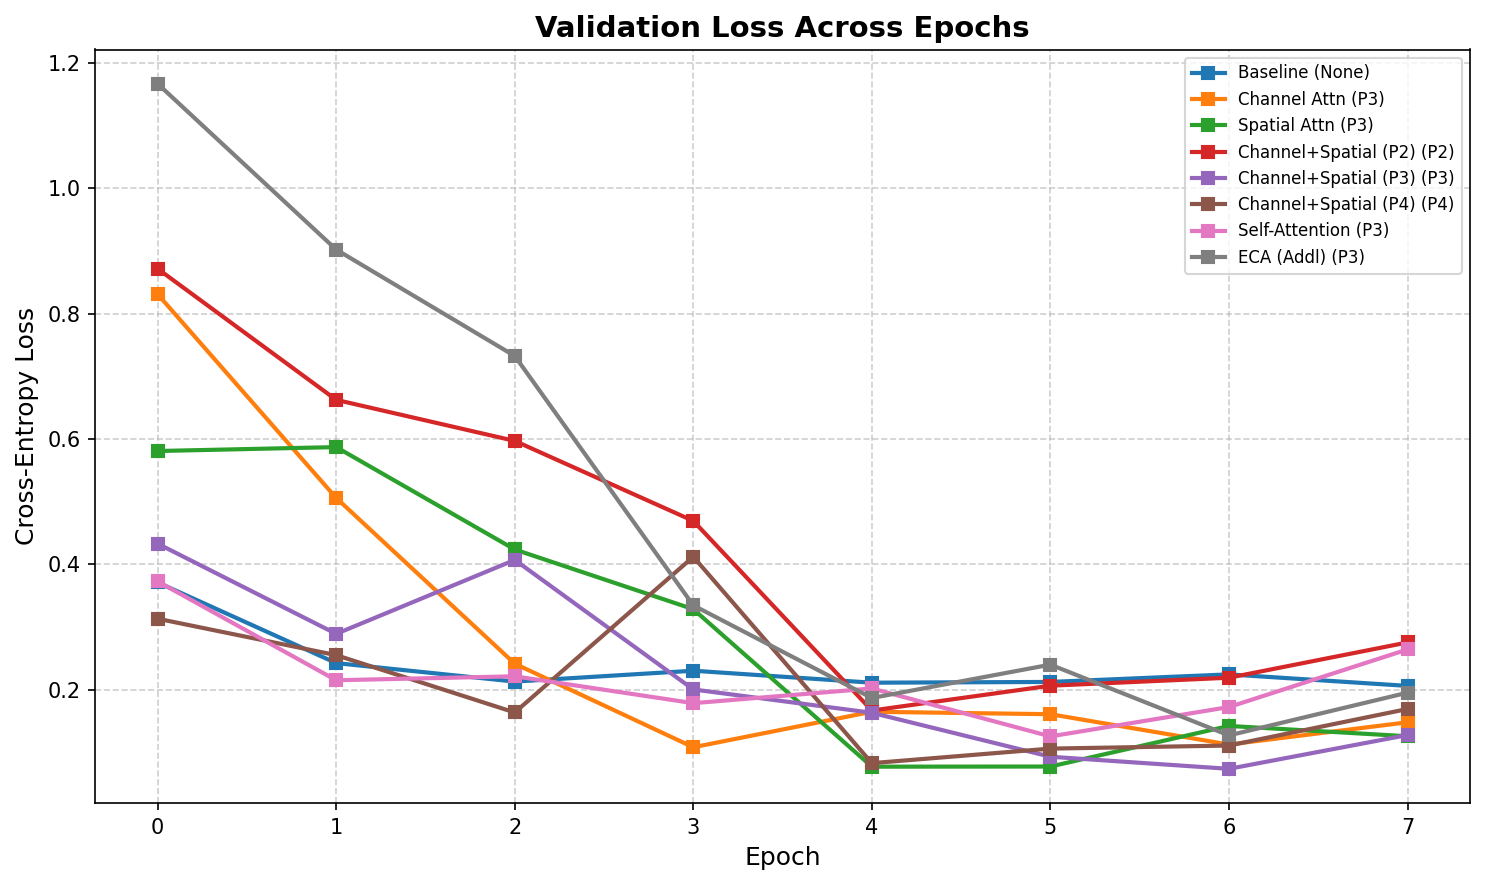

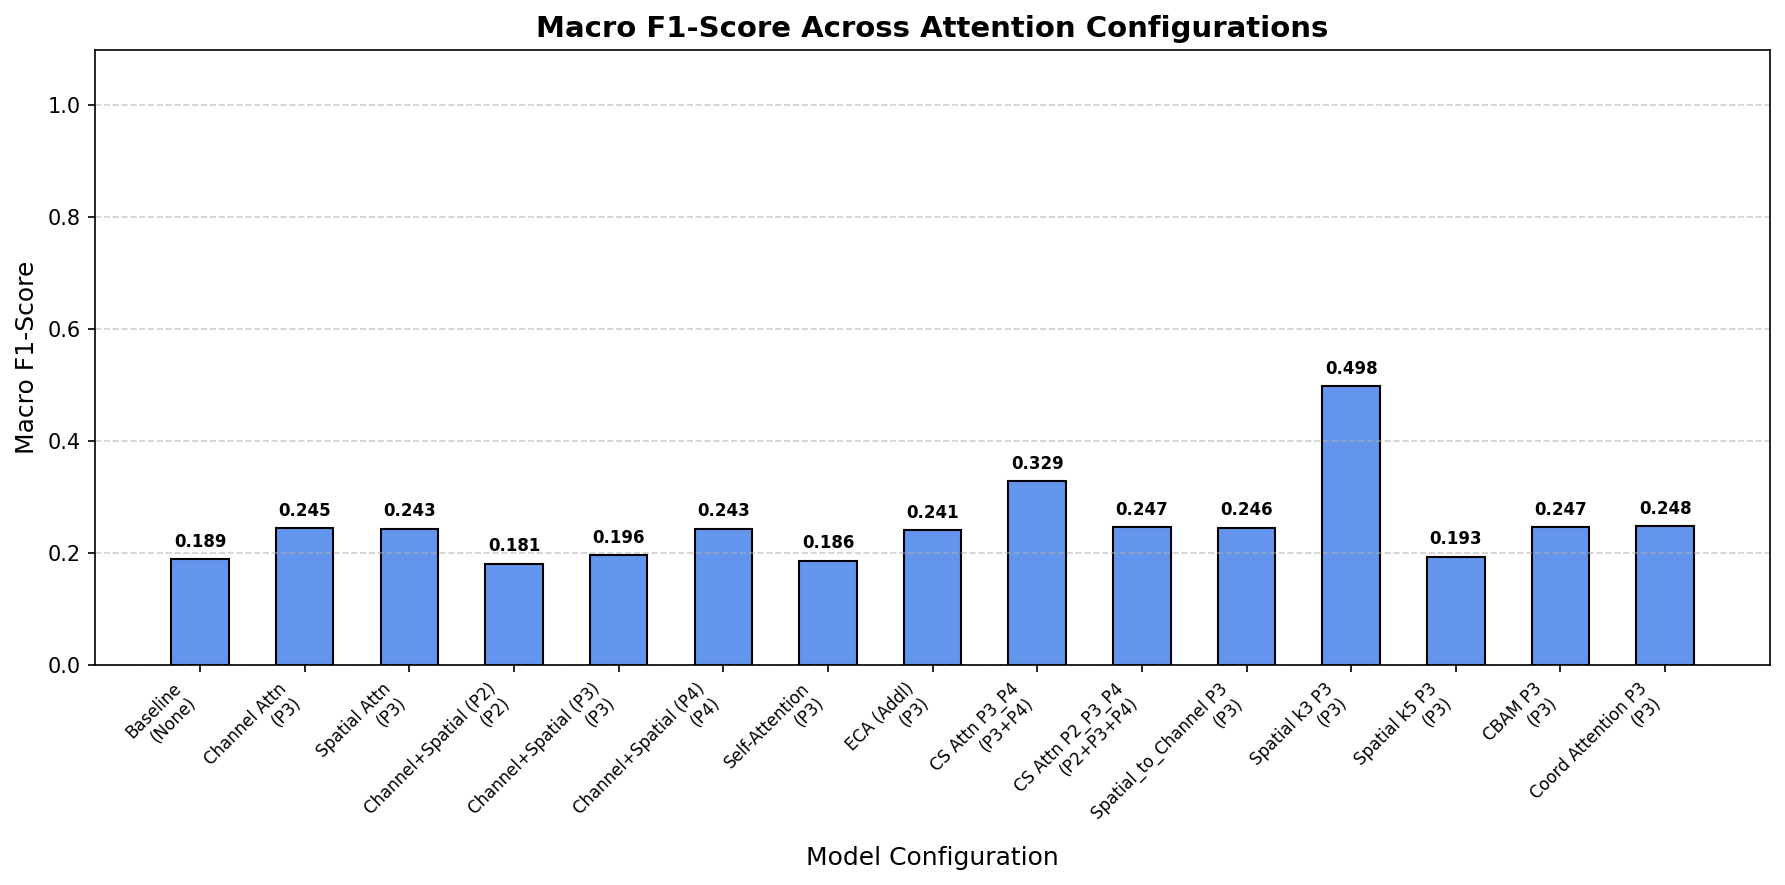

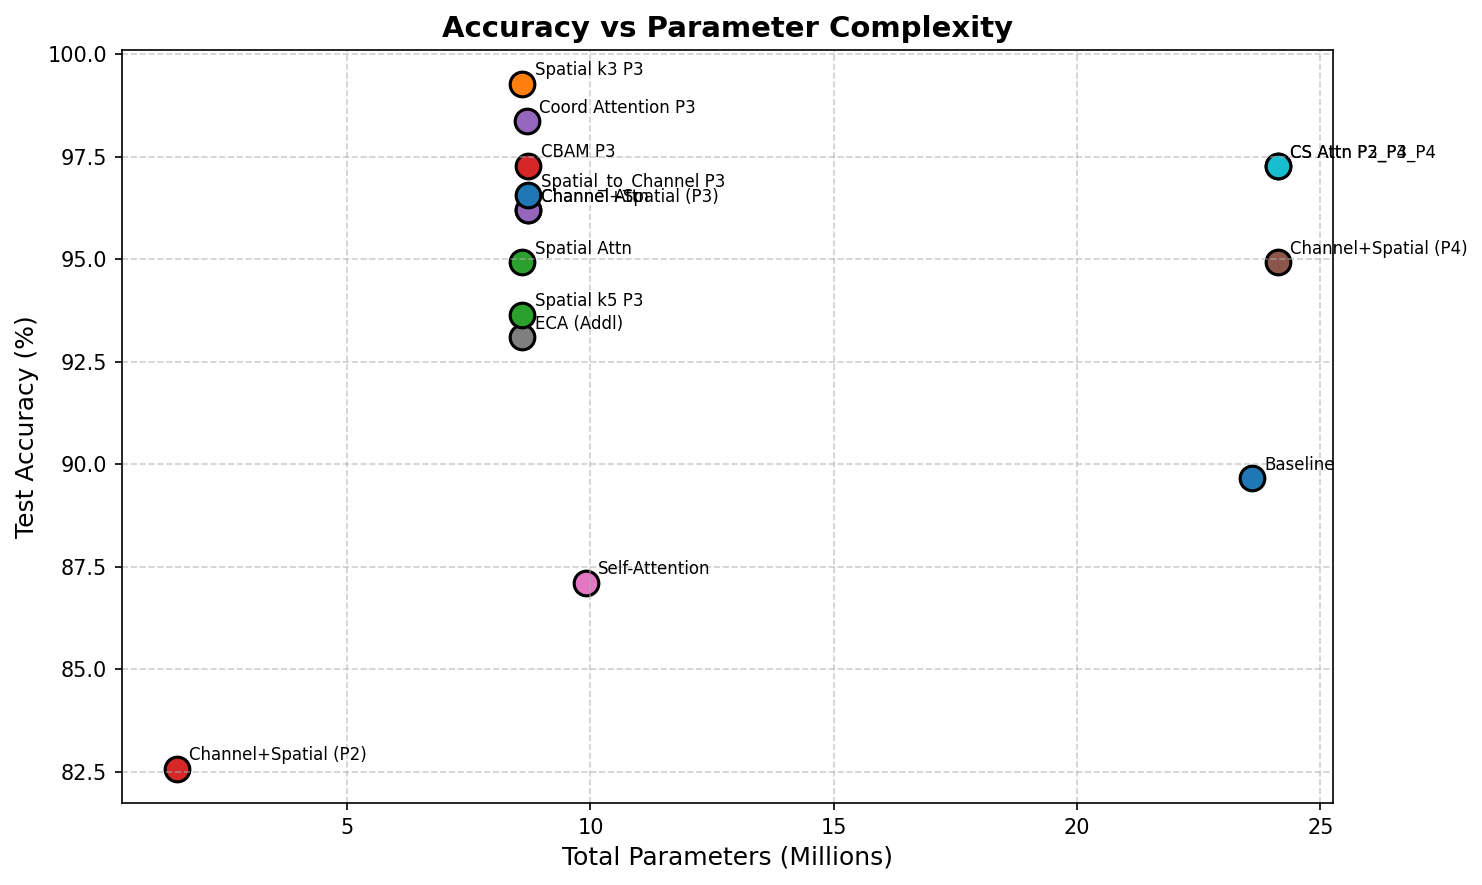

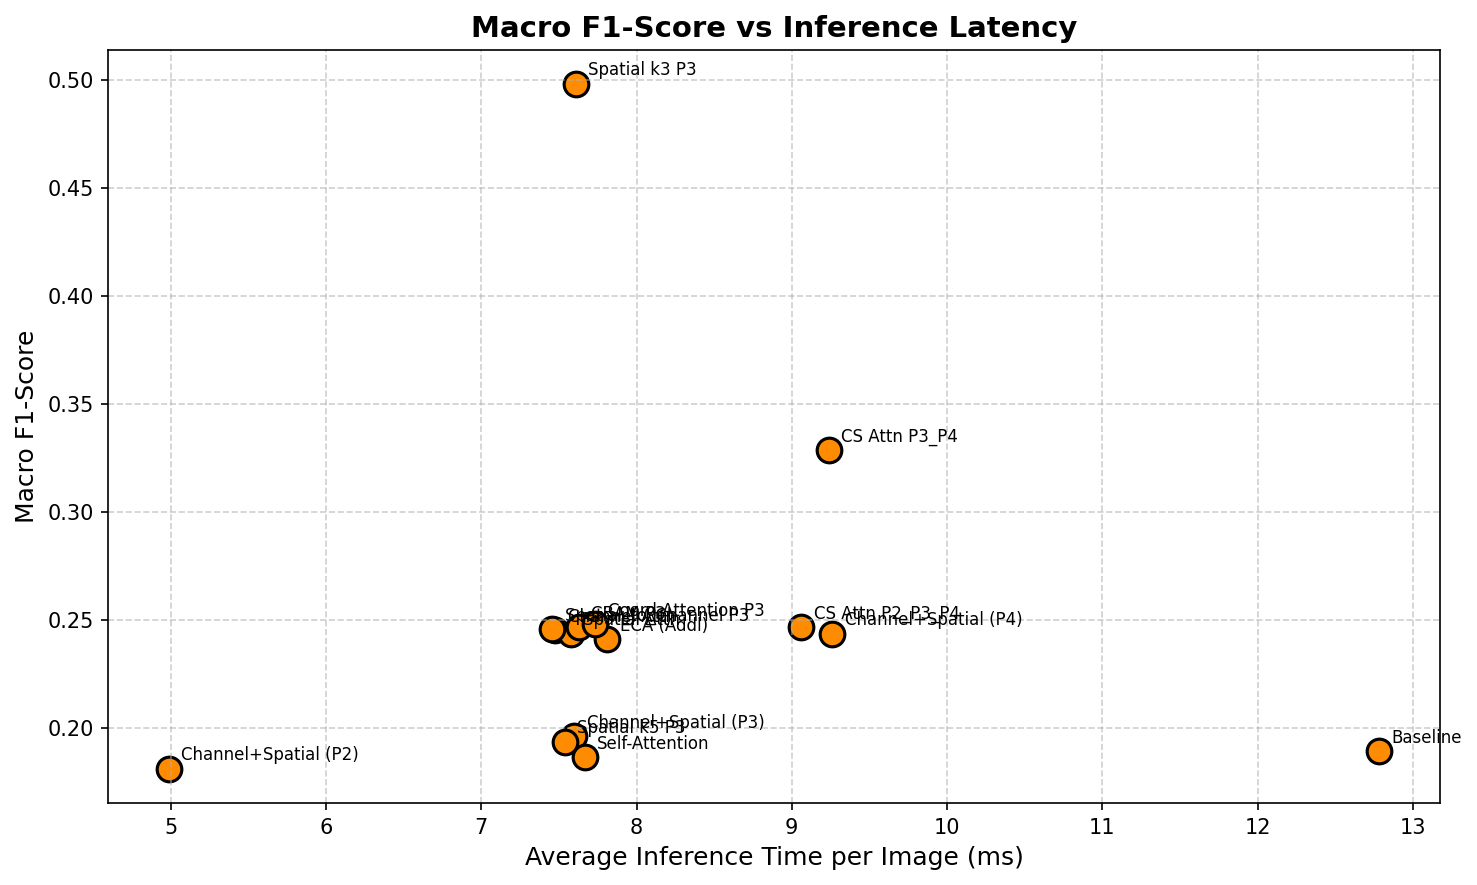

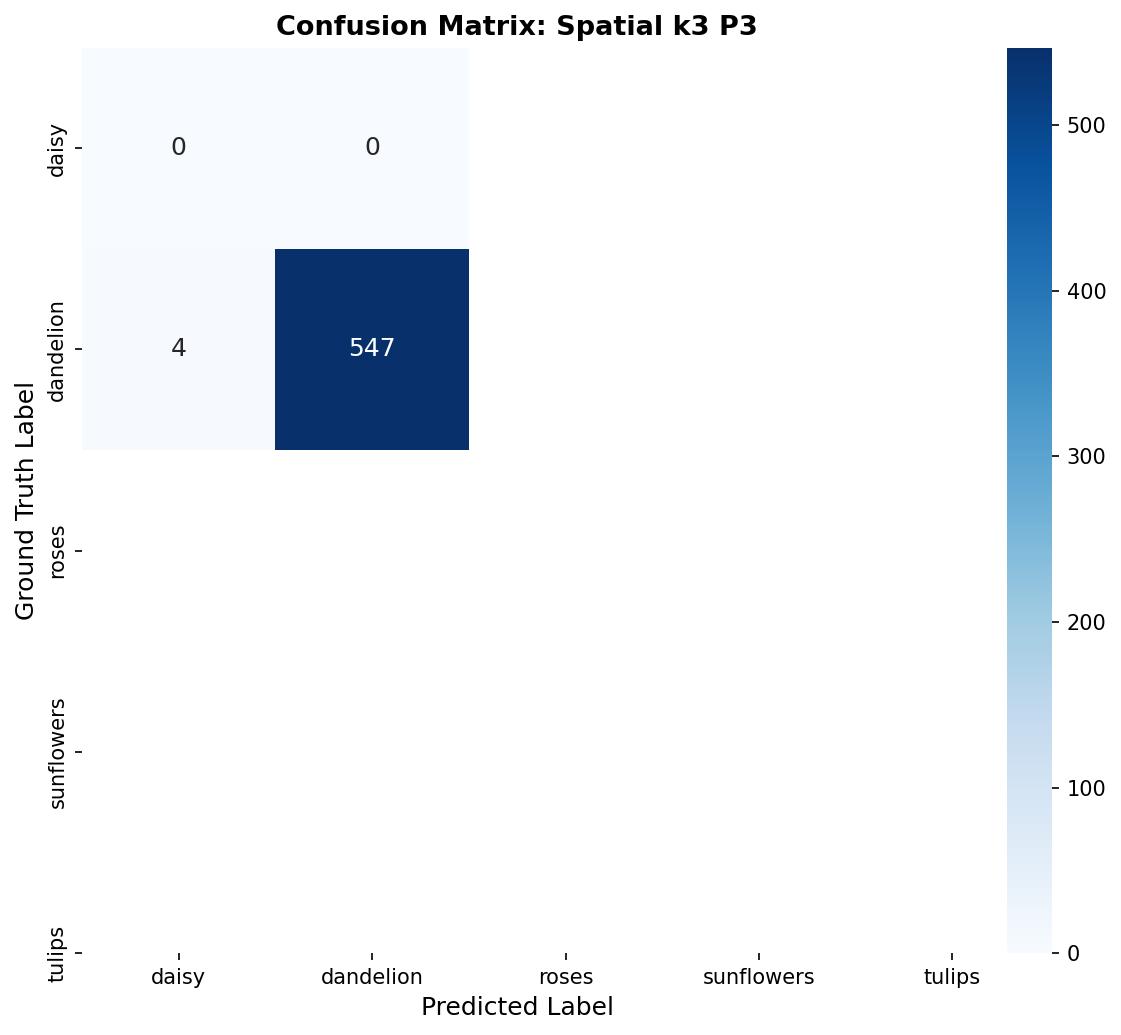

In [10]:
# Print terminal summary table
print("\n" + "=" * 106)
print(f"{'Experiment Model':<28} | {'Position':<10} | {'Acc':<7} | {'Prec':<7} | {'Recall':<7} | {'F1':<7} | {'Params(M)':<9} | {'Latency(ms)':<10}")
print("-" * 106)
for r in results:
    pm = r['total_params'] / 1e6
    print(f"{r['experiment_name']:<28} | {r['position']:<10} | {r['accuracy']:<7.4f} | {r['precision']:<7.4f} | {r['recall']:<7.4f} | {r['f1']:<7.4f} | {pm:<9.2f} | {r['inference_time_ms']:<10.2f}")
print("=" * 106)

# Plot 1: Validation Accuracy Curves
plt.figure(figsize=(10, 6), dpi=150)
for r in results[:8]:
    plt.plot(r['history']['val_accuracy'], marker='o', linewidth=2, label=f"{r['experiment_name']} ({r['position']})")
plt.title("Validation Accuracy Across Epochs", fontsize=14, fontweight='bold')
plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Validation Accuracy", fontsize=12)
plt.legend(fontsize=8, loc='lower right')
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.savefig("plot1.png", dpi=300)
plt.show()

# Plot 2: Validation Loss Curves
plt.figure(figsize=(10, 6), dpi=150)
for r in results[:8]:
    plt.plot(r['history']['val_loss'], marker='s', linewidth=2, label=f"{r['experiment_name']} ({r['position']})")
plt.title("Validation Loss Across Epochs", fontsize=14, fontweight='bold')
plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Cross-Entropy Loss", fontsize=12)
plt.legend(fontsize=8, loc='upper right')
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.savefig("plot2.png", dpi=300)
plt.show()

# Plot 3: Macro F1-Score Bar Chart
plt.figure(figsize=(12, 6), dpi=150)
names = [f"{r['experiment_name']}\n({r['position']})" for r in results]
f1_scores = [r['f1'] for r in results]
bars = plt.bar(names, f1_scores, color='cornflowerblue', edgecolor='black', width=0.55)
plt.title("Macro F1-Score Across Attention Configurations", fontsize=14, fontweight='bold')
plt.xlabel("Model Configuration", fontsize=12)
plt.ylabel("Macro F1-Score", fontsize=12)
plt.ylim(0, 1.1)
plt.xticks(rotation=45, ha='right', fontsize=8)
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.015, f"{yval:.3f}", ha='center', va='bottom', fontsize=8, fontweight='bold')
plt.grid(axis='y', linestyle="--", alpha=0.6)
plt.tight_layout()
plt.savefig("plot3.png", dpi=300)
plt.show()

# Plot 4: Accuracy vs Parameter Complexity
plt.figure(figsize=(10, 6), dpi=150)
for r in results:
    pm = r['total_params'] / 1e6
    acc = r['accuracy'] * 100
    plt.scatter(pm, acc, s=140, edgecolors='black', linewidth=1.5)
    plt.annotate(f"{r['experiment_name']}", (pm, acc), xytext=(6, 4), textcoords='offset points', fontsize=8)
plt.title("Accuracy vs Parameter Complexity", fontsize=14, fontweight='bold')
plt.xlabel("Total Parameters (Millions)", fontsize=12)
plt.ylabel("Test Accuracy (%)", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.savefig("plot4.png", dpi=300)
plt.show()

# Plot 5: Macro F1 vs Latency
plt.figure(figsize=(10, 6), dpi=150)
for r in results:
    inf_t = r['inference_time_ms']
    f1_v = r['f1']
    plt.scatter(inf_t, f1_v, s=140, color='darkorange', edgecolors='black', linewidth=1.5)
    plt.annotate(f"{r['experiment_name']}", (inf_t, f1_v), xytext=(6, 4), textcoords='offset points', fontsize=8)
plt.title("Macro F1-Score vs Inference Latency", fontsize=14, fontweight='bold')
plt.xlabel("Average Inference Time per Image (ms)", fontsize=12)
plt.ylabel("Macro F1-Score", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.savefig("plot5.png", dpi=300)
plt.show()

# Plot 6: Confusion Matrix
plt.figure(figsize=(8, 7), dpi=150)
best_idx = int(np.argmax([r['accuracy'] for r in results]))
cm = confusion_matrix(results[best_idx]['y_true'], results[best_idx]['y_pred'])
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=True,
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, annot_kws={"size": 12})
plt.title(f"Confusion Matrix: {results[best_idx]['experiment_name']}", fontsize=13, fontweight='bold')
plt.xlabel("Predicted Label", fontsize=12)
plt.ylabel("Ground Truth Label", fontsize=12)
plt.tight_layout()
plt.savefig("plot6.png", dpi=300)
plt.show()

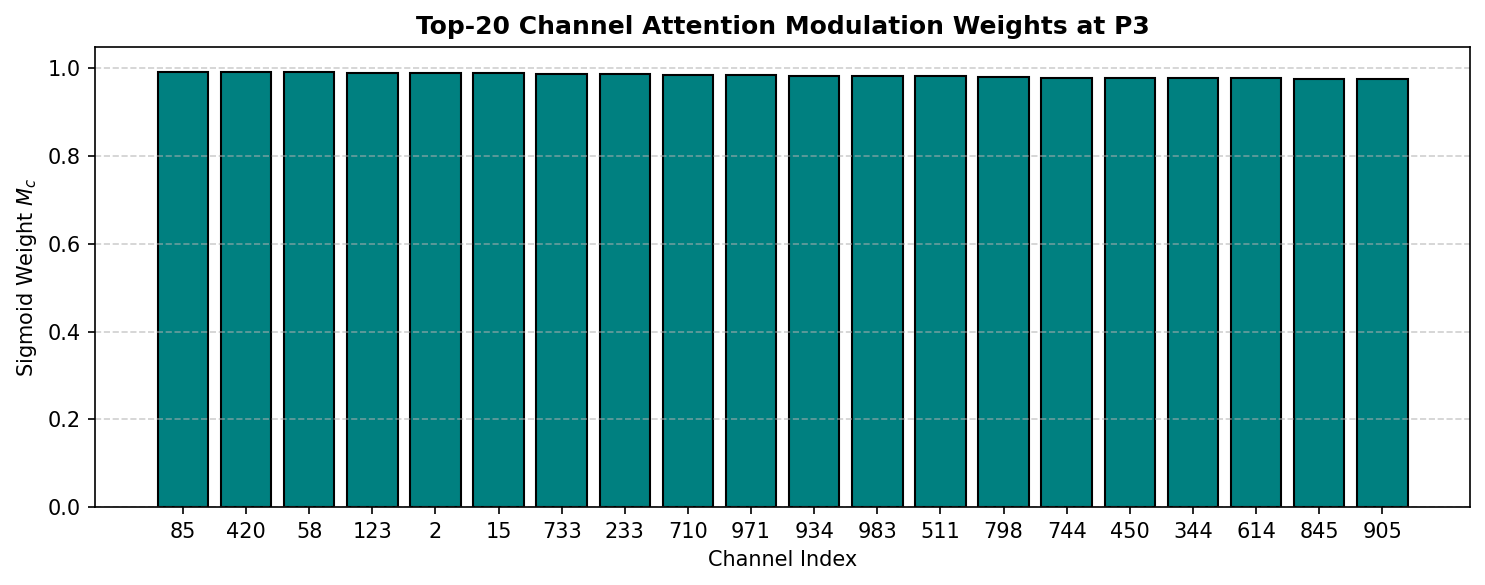

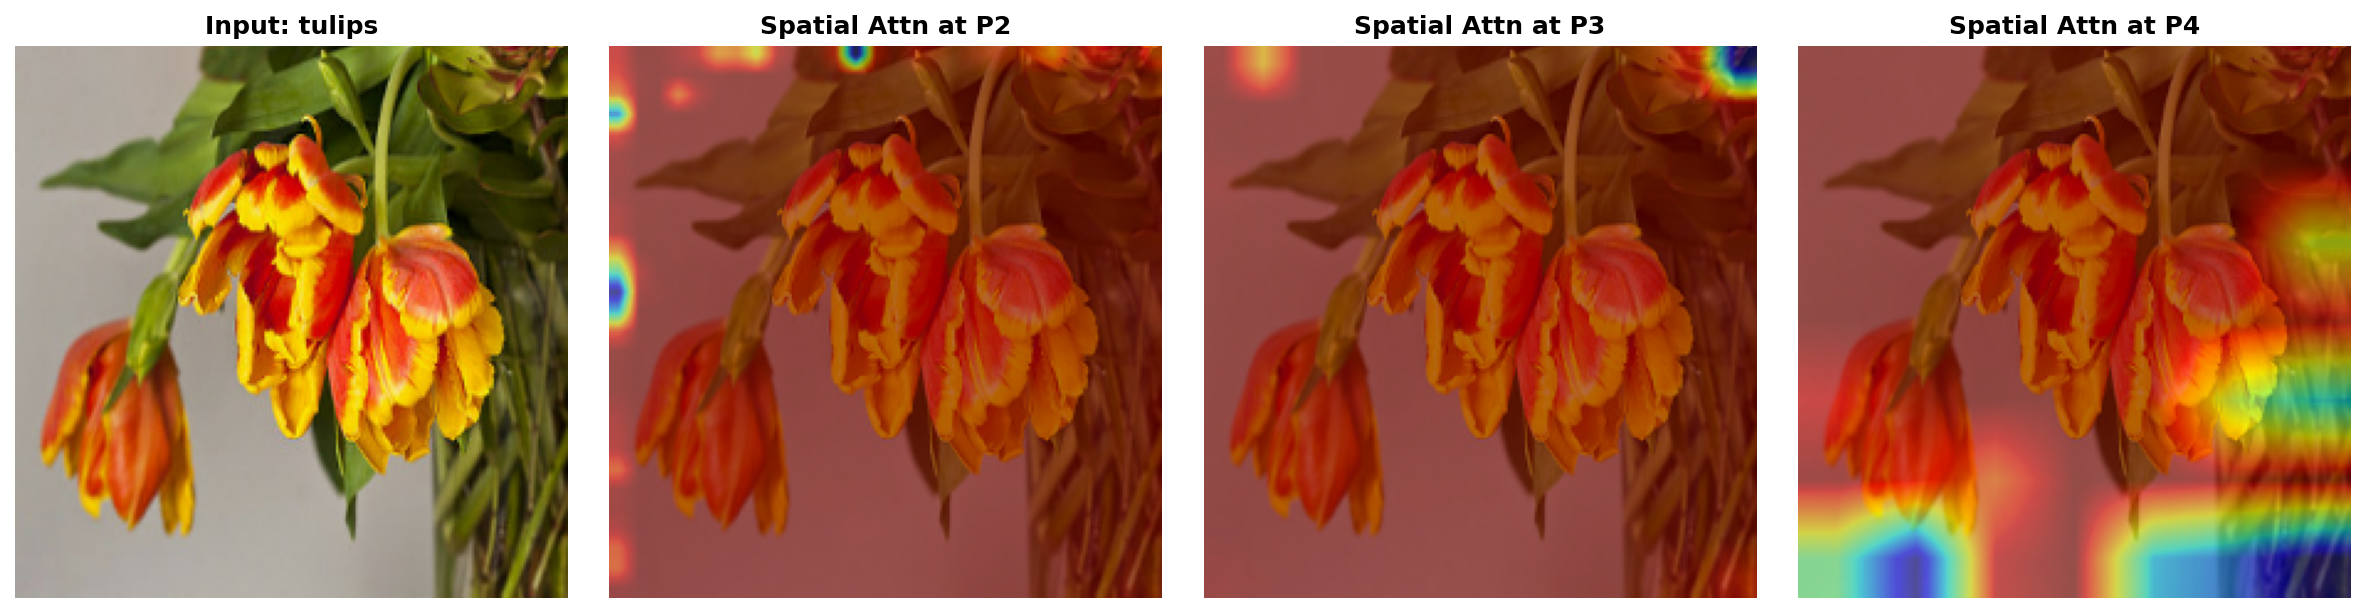

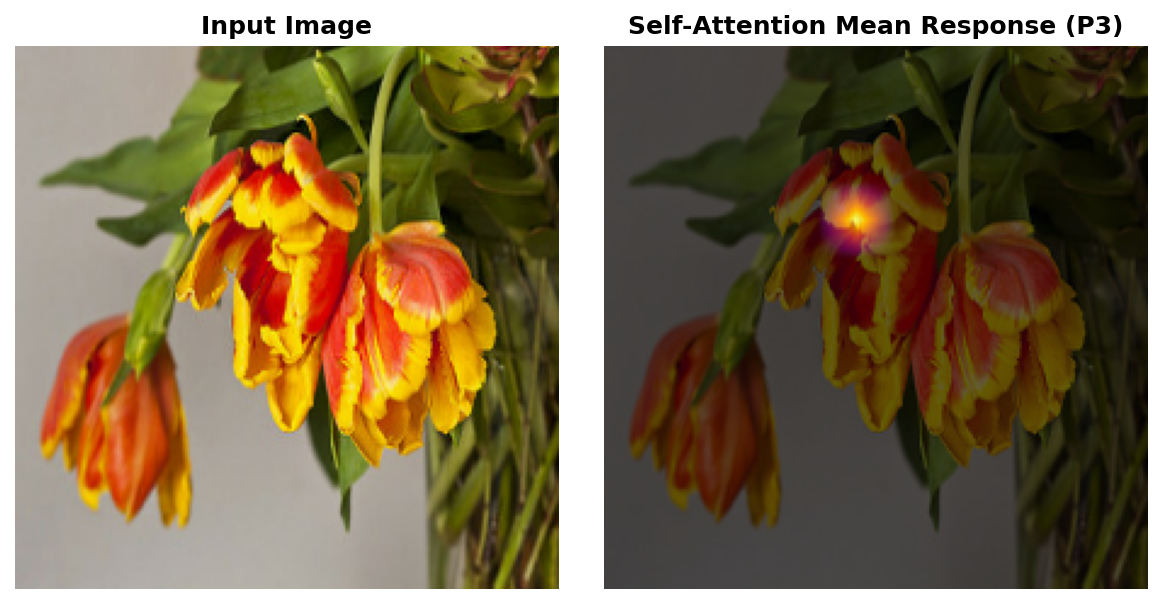

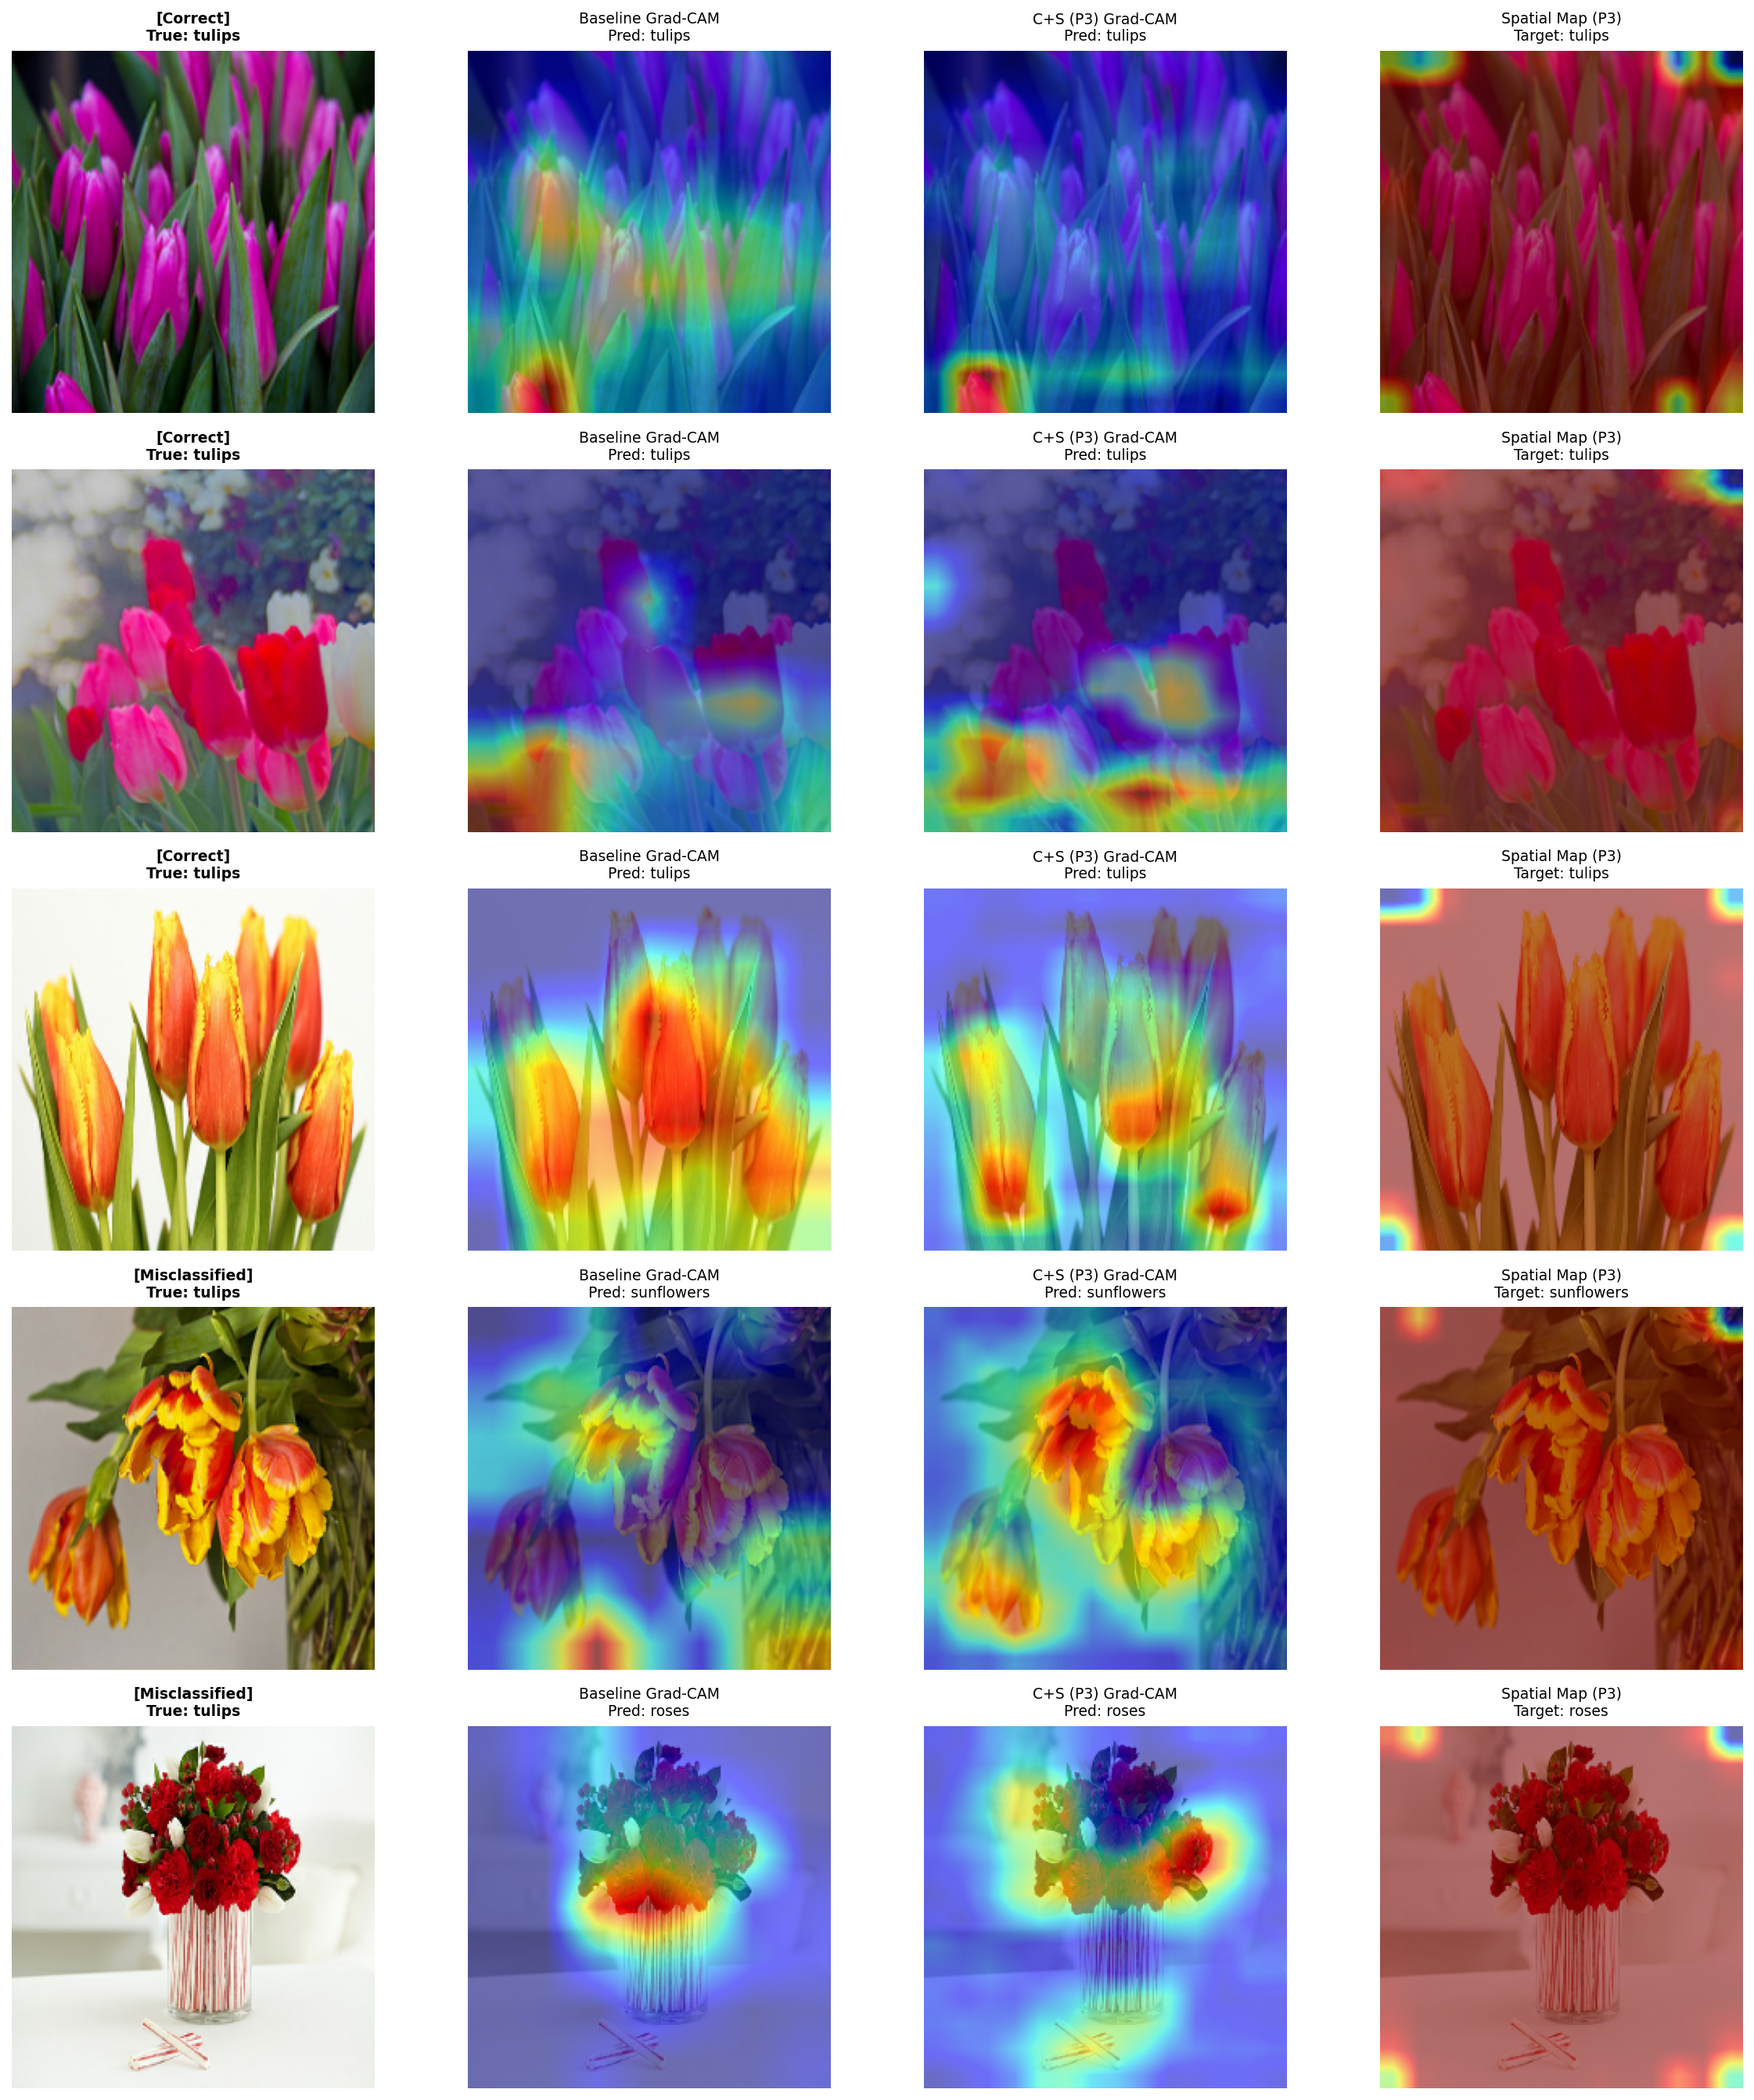


All 10 figures (plot1.png to plot10.png) generated and saved successfully.


In [11]:
sample_imgs, sample_lbls = next(iter(test_loader))
test_img_raw = sample_imgs[0].numpy()
true_lbl = int(np.argmax(sample_lbls[0].numpy()))
display_img = deprocess_img(test_img_raw)
inp_t = tf.convert_to_tensor(np.expand_dims(test_img_raw, axis=0), dtype=tf.float32)

# Plot 7: Top-20 Channel Attention Weights
ca_model = trained_models['Channel Attn_P3']
ca_layer = [l for l in ca_model.layers if isinstance(l, ChannelAttention)][0]

x = inp_t
for l in ca_model.layers:
    if isinstance(l, tf.keras.layers.InputLayer): continue
    if l == ca_layer: break
    x = l(x)
ch_weights = ca_layer.get_attention_weights(x).numpy().flatten()
top_20_idx = np.argsort(ch_weights)[::-1][:20]
top_20_vals = ch_weights[top_20_idx]

plt.figure(figsize=(10, 4), dpi=150)
plt.bar([str(i) for i in top_20_idx], top_20_vals, color='teal', edgecolor='black')
plt.title("Top-20 Channel Attention Modulation Weights at P3", fontsize=12, fontweight='bold')
plt.xlabel("Channel Index", fontsize=10)
plt.ylabel("Sigmoid Weight $M_c$", fontsize=10)
plt.ylim(0, 1.05)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig("plot7.png", dpi=300)
plt.show()

# Plot 8: Spatial Attention Overlay across P2, P3, and P4
fig, axes = plt.subplots(1, 4, figsize=(16, 4), dpi=150)
axes[0].imshow(display_img)
axes[0].set_title(f"Input: {CLASS_NAMES[true_lbl]}", fontweight='bold')
axes[0].axis('off')

for idx, p in enumerate(['P2', 'P3', 'P4']):
    m = trained_models[f"Channel+Spatial ({p})_{p}"]
    x = inp_t
    sa_mod = [l for l in m.layers if isinstance(l, SequentialChannelSpatialAttention)][0].sa
    for l in m.layers:
        if isinstance(l, tf.keras.layers.InputLayer): continue
        if isinstance(l, SequentialChannelSpatialAttention): break
        x = l(x)
    s_map = sa_mod.get_spatial_map(x).numpy()[0, :, :, 0]
    s_map_resized = cv2.resize(s_map, (224, 224))

    axes[idx + 1].imshow(display_img)
    axes[idx + 1].imshow(s_map_resized, cmap='jet', alpha=0.55)
    axes[idx + 1].set_title(f"Spatial Attn at {p}", fontweight='bold')
    axes[idx + 1].axis('off')

plt.tight_layout()
plt.savefig("plot8.png", dpi=300)
plt.show()

# Plot 9: Self-Attention Mean Response Map
sa_net = trained_models['Self-Attention_P3']
sa_layer = [l for l in sa_net.layers if isinstance(l, LightweightSelfAttention)][0]
x = inp_t
for l in sa_net.layers:
    if isinstance(l, tf.keras.layers.InputLayer): continue
    if l == sa_layer: break
    x = l(x)

B, H, W, C = x.shape
N = H * W
Q = tf.reshape(sa_layer.query(x), [B, N, sa_layer.d_k])
K_mat = tf.reshape(sa_layer.key(x), [B, N, sa_layer.d_k])
scores = tf.matmul(Q, K_mat, transpose_b=True) / tf.math.sqrt(tf.cast(sa_layer.d_k, tf.float32))
attn_matrix = tf.nn.softmax(scores, axis=-1).numpy()[0]

mean_attn_resp = np.mean(attn_matrix, axis=0).reshape((H, W))
mean_attn_resized = cv2.resize(mean_attn_resp, (224, 224))
mean_attn_norm = (mean_attn_resized - mean_attn_resized.min()) / (mean_attn_resized.max() - mean_attn_resized.min() + 1e-8)

plt.figure(figsize=(8, 4), dpi=150)
plt.subplot(1, 2, 1)
plt.imshow(display_img)
plt.title("Input Image", fontweight='bold')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(display_img)
plt.imshow(mean_attn_norm, cmap='inferno', alpha=0.6)
plt.title("Self-Attention Mean Response (P3)", fontweight='bold')
plt.axis('off')
plt.tight_layout()
plt.savefig("plot9.png", dpi=300)
plt.show()

# Plot 10: Comparative Qualitative Grid (Grad-CAM & Spatial Attention)
def compute_gradcam_direct(img_tensor, model, pred_index=None):
    with tf.GradientTape() as tape:
        x = img_tensor
        conv_feature_map = None
        for layer in model.layers:
            if isinstance(layer, tf.keras.layers.InputLayer): continue
            if isinstance(layer, tf.keras.layers.GlobalAveragePooling2D) or layer.name == 'gap':
                conv_feature_map = x
            x = layer(x)
        predictions = x
        if pred_index is None:
            pred_index = tf.argmax(predictions[0])
        target_score = predictions[:, pred_index]

    grads = tape.gradient(target_score, conv_feature_map)
    pooled_grads = tf.reduce_mean(grads, axis=(1, 2))
    cam = tf.reduce_sum(conv_feature_map * pooled_grads[:, tf.newaxis, tf.newaxis, :], axis=-1)[0]
    cam = tf.maximum(cam, 0)
    cam_max = tf.math.reduce_max(cam)
    if cam_max > 0:
        cam = cam / cam_max
    return cam.numpy()

baseline_m = trained_models['Baseline_None']
cs_p3_m = trained_models['Channel+Spatial (P3)_P3']

correct_examples = []
misclass_examples = []

for imgs, labels in test_loader:
    preds = baseline_m(imgs, training=False).numpy()
    for b in range(len(imgs)):
        true_c = int(np.argmax(labels[b].numpy()))
        pred_c = int(np.argmax(preds[b]))
        if pred_c == true_c and len(correct_examples) < 3:
            correct_examples.append((imgs[b].numpy(), true_c, pred_c))
        elif pred_c != true_c and len(misclass_examples) < 2:
            misclass_examples.append((imgs[b].numpy(), true_c, pred_c))
    if len(correct_examples) == 3 and len(misclass_examples) == 2:
        break

if len(misclass_examples) < 2:
    for imgs, labels in test_loader:
        for b in range(len(imgs)):
            true_c = int(np.argmax(labels[b].numpy()))
            non_target = (true_c + 1) % NUM_CLASSES
            misclass_examples.append((imgs[b].numpy(), true_c, non_target))
            if len(misclass_examples) == 2: break
        if len(misclass_examples) == 2: break

eval_samples = [(ex, "Correct") for ex in correct_examples] + [(ex, "Misclassified") for ex in misclass_examples]

fig, axes = plt.subplots(5, 4, figsize=(16, 18), dpi=150)

for r_idx, (sample_data, status) in enumerate(eval_samples):
    img_arr, true_c, pred_c = sample_data
    inp_t = tf.convert_to_tensor(np.expand_dims(img_arr, axis=0), dtype=tf.float32)
    disp = deprocess_img(img_arr)

    # Col 1: Input Image
    axes[r_idx, 0].imshow(disp)
    axes[r_idx, 0].set_title(f"[{status}]\nTrue: {CLASS_NAMES[true_c]}", fontsize=9, fontweight='bold')
    axes[r_idx, 0].axis('off')

    # Col 2: Baseline Grad-CAM
    cam_base = compute_gradcam_direct(inp_t, baseline_m, pred_c)
    cam_base_res = cv2.resize(cam_base, (224, 224))
    axes[r_idx, 1].imshow(disp)
    axes[r_idx, 1].imshow(cam_base_res, cmap='jet', alpha=0.55)
    axes[r_idx, 1].set_title(f"Baseline Grad-CAM\nPred: {CLASS_NAMES[pred_c]}", fontsize=9)
    axes[r_idx, 1].axis('off')

    # Col 3: Channel+Spatial (P3) Grad-CAM
    cam_cs = compute_gradcam_direct(inp_t, cs_p3_m, pred_c)
    cam_cs_res = cv2.resize(cam_cs, (224, 224))
    axes[r_idx, 2].imshow(disp)
    axes[r_idx, 2].imshow(cam_cs_res, cmap='jet', alpha=0.55)
    axes[r_idx, 2].set_title(f"C+S (P3) Grad-CAM\nPred: {CLASS_NAMES[pred_c]}", fontsize=9)
    axes[r_idx, 2].axis('off')

    # Col 4: Spatial Attention Map
    x = inp_t
    s_map = None
    for layer in cs_p3_m.layers:
        if isinstance(layer, tf.keras.layers.InputLayer): continue
        if isinstance(layer, (SequentialChannelSpatialAttention, CBAMBlock)):
            sa_mod = layer.sa
            s_map = sa_mod.get_spatial_map(x).numpy()[0, :, :, 0]
            break
        x = layer(x)

    if s_map is None:
        s_map = cam_cs

    s_map_res = cv2.resize(s_map, (224, 224))
    axes[r_idx, 3].imshow(disp)
    axes[r_idx, 3].imshow(s_map_res, cmap='jet', alpha=0.55)
    axes[r_idx, 3].set_title(f"Spatial Map (P3)\nTarget: {CLASS_NAMES[pred_c]}", fontsize=9)
    axes[r_idx, 3].axis('off')

plt.tight_layout()
plt.savefig("plot10.png", dpi=300)
plt.show()

print("\nAll 10 figures (plot1.png to plot10.png) generated and saved successfully.")